In [ ]:
# Locate the repository root (works regardless of the launch directory) and expose it on sys.path.
import os, sys
_p = os.path.abspath(os.getcwd())
while _p != os.path.dirname(_p) and not os.path.exists(os.path.join(_p, 'src', 'config.py')):
    _p = os.path.dirname(_p)
BASE = _p
sys.path.insert(0, BASE)
sys.path.insert(0, os.path.join(BASE, 'ana'))
from src.config import BIOMEDBERT


# Mechanism-alignment figures

Run the switch cell first, then the cells top-to-bottom. Loads the `mech_align_emb` cache; no GPU or model needed.


In [ ]:
# Fold-split switch (run this cell first).
# PROMPTCASL_SPLIT selects the fold split read by the interpretation cells: 'gplo' or 'std'.
import os, sys, datetime
os.environ['PROMPTCASL_SPLIT'] = 'gplo'
sys.path.insert(0, os.path.join(BASE, 'ana'))
import model_version as MV
print(MV.summary())


In [2]:
import sys, os
sys.path.insert(0, os.path.join(BASE, 'ana'))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import textwrap
import lit_mech_casestudy as L

pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 80)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})

BASE = L.BASE
CL6 = L.CELL_LINES
CL_COLORS = {'A549':'#e41a1c','PK1':'#377eb8','IPC298':'#4daf4a',
             'MEWO':'#984ea3','GI1':'#ff7f00','HS936T':'#a65628'}

cand = L.build_candidates()
pred_full  = L.load_predictions(L.PRED_FULL)
pred_blind = L.load_predictions(L.PRED_BLIND)
print(f'candidate pairs (evaluated x lit-mechanism): {len(cand)}')
print('by subset:', cand.subset.value_counts().to_dict())

candidate pairs (evaluated x lit-mechanism): 113
by subset: {'single': 60, 'consistent': 40, 'conflict': 13}


### Mechanism-alignment distribution (GPLO)

`top1_pctile` (best-attended pathway) and `sem_topk_pctile` (best of top-5) over the solid pairs.


In [3]:
# reload modules
import importlib, lit_mech_casestudy, mechanism_alignment
importlib.reload(lit_mech_casestudy); importlib.reload(mechanism_alignment)
import mechanism_alignment as M
from scipy.stats import wilcoxon, binomtest
cand = lit_mech_casestudy.build_candidates()   # refresh cand from reloaded module (self-sufficient)

align = M.build_alignment()          # loads mech_align_emb.npz cache -> offline
print(f'solid pairs with Reactome attention: {len(align)}  '
      f'(of {int(cand.solid.sum())} solid; rest have no Reactome evidence token)')

w = wilcoxon(align.top1_pctile - 0.5, alternative='greater')
w_stk = wilcoxon(align.sem_topk_pctile - align.null_topk, alternative='greater')  # vs proper max-of-5 null, NOT 0.5
w_pair = wilcoxon(align.sem_topk_pctile - align.top1_pctile, alternative='greater')  # lenient >= strict by construction
bg = binomtest(int((align.sem_gain > 0).sum()), len(align), 0.5, 'greater')
print(f'\ntop1 mechanism-cosine percentile: mean={align.top1_pctile.mean():.3f}  '
      f'(random=0.50)  Wilcoxon vs 0.5 p={w.pvalue:.1e}')
print(f'sem_topk (top-5) percentile     : mean={align.sem_topk_pctile.mean():.3f}  '
      f'(max-of-5 null {align.null_topk.mean():.3f})  Wilcoxon vs null p={w_stk.pvalue:.1e}   '
      f'paired stk-top1 Delta={(align.sem_topk_pctile - align.top1_pctile).mean():+.3f} p={w_pair.pvalue:.1e}')
print(f'attention up-weights mechanism-aligned pathways: sem_gain>0 in '
      f'{(align.sem_gain>0).sum()}/{len(align)} (binom p={bg.pvalue:.1e}); '
      f'mean attn-cos Spearman rho={align.attn_cos_rho.mean():.3f}')
print(f'\nsemantic-aligned (top1 in top-10% mechanism-similar): '
      f'{align.sem_aligned.sum()} ({align.sem_aligned.mean():.0%})')
print(f'keyword-aligned  (theme hit in top-5 attended)       : '
      f'{align.kw_aligned.sum()} ({align.kw_aligned.mean():.0%})')
print(f'both: {align.both_aligned.sum()}   either: {align.either_aligned.sum()}')

solid pairs with Reactome attention: 49  (of 81 solid; rest have no Reactome evidence token)

top1 mechanism-cosine percentile: mean=0.610  (random=0.50)  Wilcoxon vs 0.5 p=4.4e-03
sem_topk (top-5) percentile     : mean=0.850  (max-of-5 null 0.827)  Wilcoxon vs null p=2.7e-03   paired stk-top1 Delta=+0.240 p=1.8e-07
attention up-weights mechanism-aligned pathways: sem_gain>0 in 33/49 (binom p=1.1e-02); mean attn-cos Spearman rho=0.143

semantic-aligned (top1 in top-10% mechanism-similar): 8 (16%)
keyword-aligned  (theme hit in top-5 attended)       : 22 (45%)
both: 2   either: 28


/home/tinglu/anaconda3/envs/llm4sl/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  res = hypotest_fun_out(*samples, **kwds)


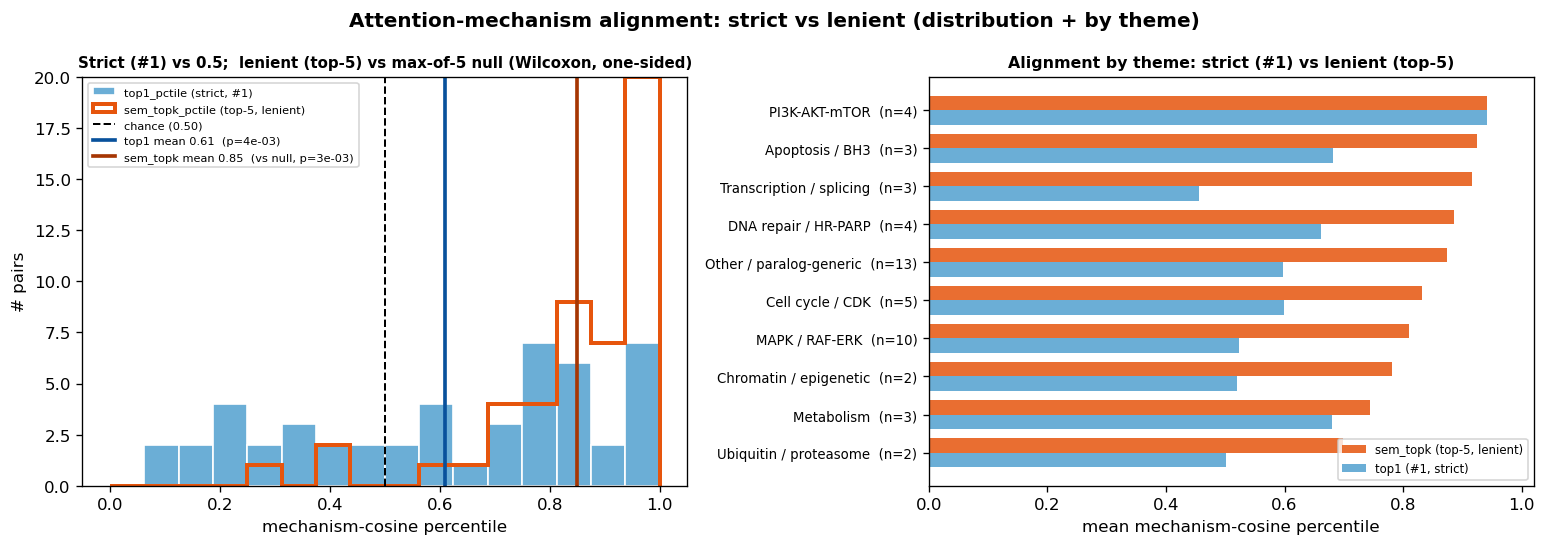

=== semantically-aligned subset (top1 in top-10% mechanism-similar) ===
             pk     subset                   theme  sl_prob                                                                                                     top1_pathway  top1_pctile  sem_topk_pctile  kw_rank
    CNOT7|CNOT8     single Other / paralog-generic 0.999822 TP53_REGULATES_TRANSCRIPTION_OF_ADDITIONAL_CELL_CYCLE_GENES_WHOSE_EXACT_ROLE_IN_THE_P53_PATHWAY_REMAIN_UNCERTAIN        0.999            0.999      NaN
RPS6KA1|RPS6KB1 consistent          MAPK / RAF-ERK 0.985371                                 CREB1_PHOSPHORYLATION_THROUGH_NMDA_RECEPTOR_MEDIATED_ACTIVATION_OF_RAS_SIGNALING        0.978            0.978     11.0
      AKT1|AKT3     single           PI3K-AKT-mTOR 0.735116                                                                      REGULATION_OF_GENE_EXPRESSION_IN_BETA_CELLS        0.954            0.954      4.0
      AKT1|AKT2   conflict           PI3K-AKT-mTOR 0.975675                     

In [4]:
m1, m2 = align.top1_pctile.mean(), align.sem_topk_pctile.mean()   # top1 vs 0.5; sem_topk vs max-of-5 null (significance in §6a-compute; line not drawn)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# (left) strict #1 (top1_pctile) vs lenient top-5 (sem_topk_pctile): distributions + means + significance vs chance
ax = axes[0]
ax.hist(align.top1_pctile, bins=16, range=(0, 1), color='#6baed6', edgecolor='w',
        label='top1_pctile (strict, #1)')
ax.hist(align.sem_topk_pctile, bins=16, range=(0, 1), histtype='step', lw=2.4, color='#e6550d',
        label='sem_topk_pctile (top-5, lenient)')
ax.axvline(0.5, color='k', ls='--', lw=1.2, label='chance (0.50)')
ax.axvline(m1, color='#08519c', lw=2.2, label=f'top1 mean {m1:.2f}  (p={w.pvalue:.0e})')
ax.axvline(m2, color='#a63603', lw=2.2, label=f'sem_topk mean {m2:.2f}  (vs null, p={w_stk.pvalue:.0e})')
ax.set_ylim(0, 20) 
ax.set_xlabel('mechanism-cosine percentile'); ax.set_ylabel('# pairs'); ax.legend(fontsize=6.8, loc='upper left')
ax.set_title('Strict (#1) vs 0.5;  lenient (top-5) vs max-of-5 null (Wilcoxon, one-sided)',
             fontweight='bold', fontsize=9)

# (right) per-theme: strict top1 (blue) vs lenient sem_topk (orange) grouped bars.
# blue/orange gap = difference between the strict top-1 and top-5 metrics.
th = align.groupby('theme').agg(n=('pk', 'size'), top1=('top1_pctile', 'mean'),
                                stk=('sem_topk_pctile', 'mean')).sort_values('stk')
y = np.arange(len(th)); hbar = 0.38
ax = axes[1]
ax.barh(y + hbar / 2, th.stk, hbar, color='#e6550d', alpha=.85, label='sem_topk (top-5, lenient)')
ax.barh(y - hbar / 2, th.top1, hbar, color='#6baed6', label='top1 (#1, strict)')
ax.set_yticks(y); ax.set_yticklabels([f'{t}  (n={int(n)})' for t, n in zip(th.index, th.n)], fontsize=8)
ax.set_xlim(0, 1.02); ax.set_xlabel('mean mechanism-cosine percentile')
ax.legend(fontsize=7, loc='lower right')
ax.set_title('Alignment by theme: strict (#1) vs lenient (top-5)', fontweight='bold', fontsize=9.5)
plt.suptitle('Attention-mechanism alignment: strict vs lenient (distribution + by theme)',
             fontweight='bold'); plt.tight_layout(); plt.show()

print('=== semantically-aligned subset (top1 in top-10% mechanism-similar) ===')
print(align[align.sem_aligned][['pk', 'subset', 'theme', 'sl_prob', 'top1_pathway',
                                'top1_pctile', 'sem_topk_pctile', 'kw_rank']].to_string(index=False))


### Distribution plots

Alternative renderings of the same two distributions.


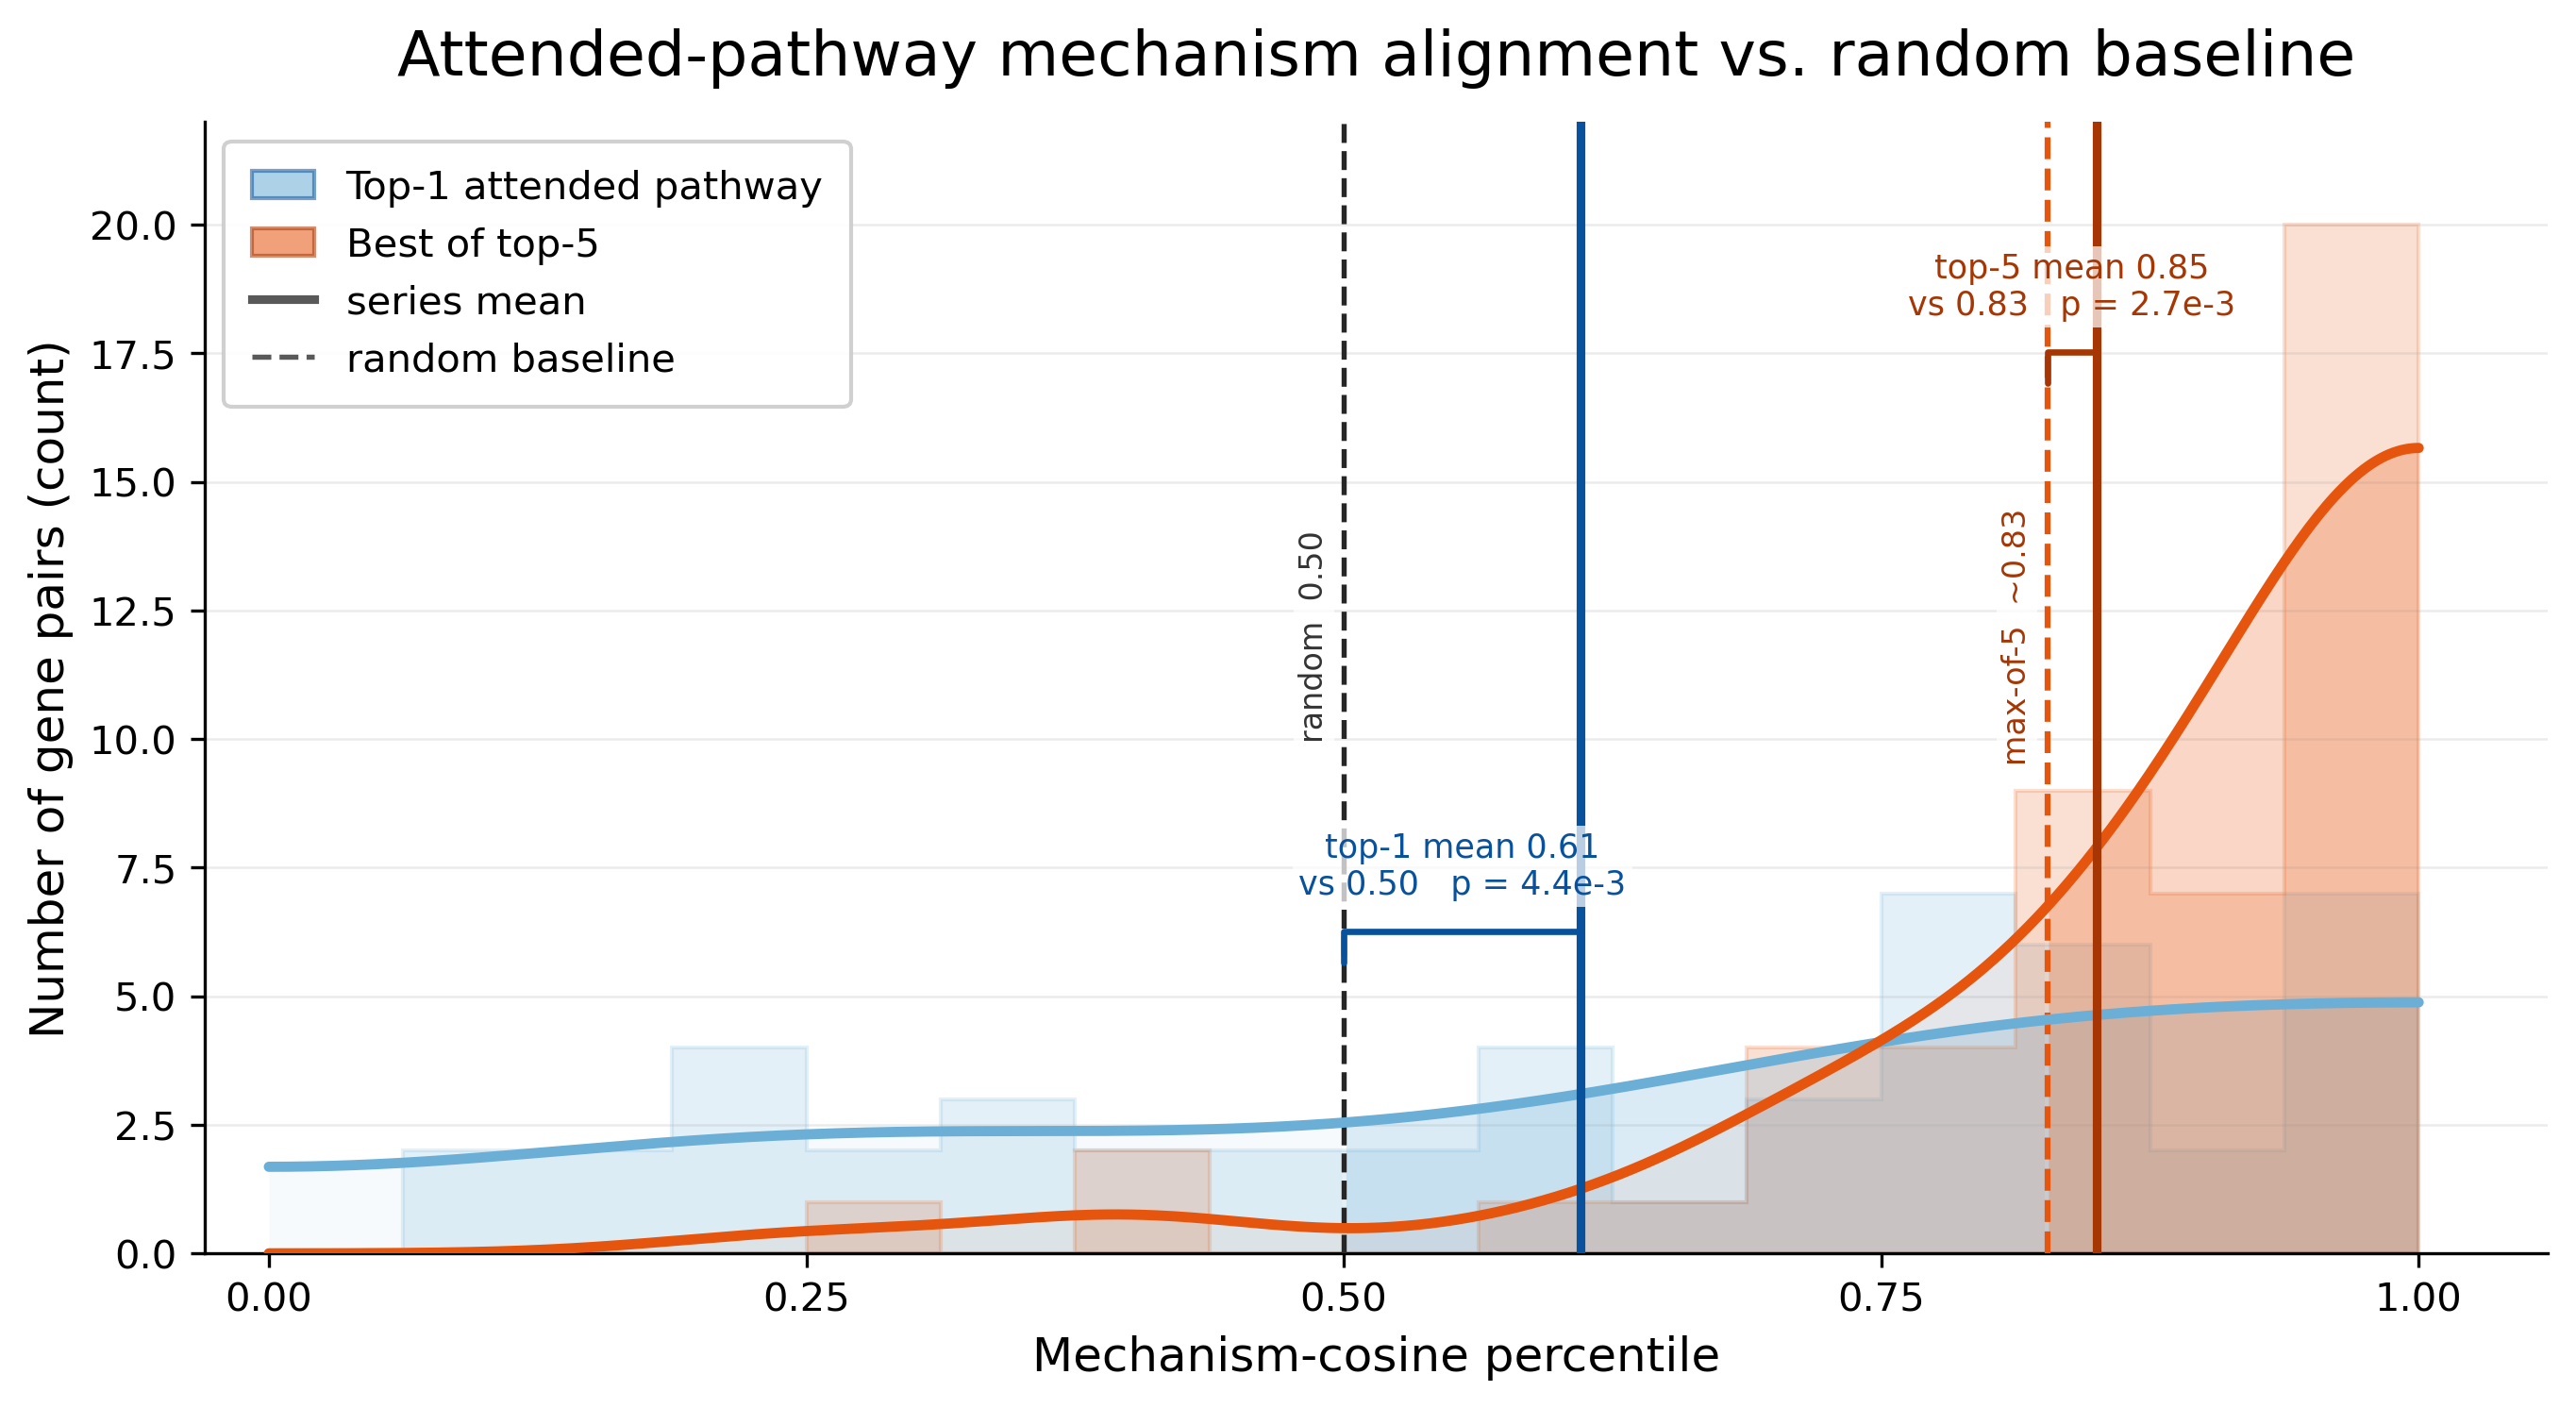

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ----------------------- KNOBS -----------------------
FIGSIZE    = (9.2, 5.4)
NBINS      = 16          # few bins -> a continuous, gap-free background histogram
BW_SCALE   = 1.30        # KDE bandwidth scale relative to Silverman (>1 = smoother)
BW_FLOOR   = 0.040       # bandwidth floor to suppress jitter at n=49
GRID_N     = 512
HIST_ALPHA = 0.18        # background histogram opacity
FILL_R     = 0.24        # KDE fill: right of baseline (more solid)
FILL_L     = 0.06        # KDE fill: left of baseline (fainter)
KDE_LW     = 2.6
YHEAD      = 1.1        # headroom above the y-axis
BLUE       = '#6baed6';  BLUE_DARK   = '#08519c'
ORANGE     = '#e6550d';  ORANGE_DARK = '#a63603'

# ----------------- stats guards -----------------
_w  = globals().get('w')
_ws = globals().get('w_stk')
if _w is None or _ws is None:
    from scipy.stats import wilcoxon
    if _w  is None: _w  = wilcoxon(align.top1_pctile - 0.5,
                                   alternative='greater')
    if _ws is None: _ws = wilcoxon(align.sem_topk_pctile - align.null_topk,
                                   alternative='greater')
p_blue = float(_w.pvalue)
p_org  = float(_ws.pvalue)

# ----------------------- data -----------------------
x_blue = np.asarray(align.top1_pctile,     float)
x_org  = np.asarray(align.sem_topk_pctile, float)
n      = len(x_blue)
m1     = float(x_blue.mean())
m2     = float(x_org.mean())
nullm  = float(align.null_topk.mean())      # ~0.83  orange null baseline (max-of-5)
_trapz = getattr(np, 'trapezoid', np.trapz)

# ---------- boundary-reflected gaussian KDE on [0,1] ----------
def silverman_bw(x):
    x = np.asarray(x, float); nn = len(x)
    sd = np.std(x, ddof=1)
    q75, q25 = np.percentile(x, [75, 25]); iqr = q75 - q25
    a = min(sd, iqr / 1.349) if iqr > 0 else sd
    if not np.isfinite(a) or a <= 0: a = 0.1
    return max(0.9 * a * nn ** (-1.0/5.0) * BW_SCALE, BW_FLOOR)

def kde_reflected(x, grid, bw):
    x  = np.asarray(x, float)
    xr = np.concatenate([-x, x, 2.0 - x])           # reflect about 0 and 1
    d  = (grid[:, None] - xr[None, :]) / bw
    k  = np.exp(-0.5 * d * d) / (bw * np.sqrt(2.0 * np.pi))
    dens = k.sum(axis=1) / len(x)
    area = _trapz(dens, grid)
    if area > 0: dens = dens / area                 # renormalize -> no leak past [0,1]
    return dens

grid   = np.linspace(0.0, 1.0, GRID_N)
edges  = np.linspace(0.0, 1.0, NBINS + 1)
binw   = 1.0 / NBINS
d_blue = kde_reflected(x_blue, grid, silverman_bw(x_blue)) * n * binw   # -> count scale
d_org  = kde_reflected(x_org,  grid, silverman_bw(x_org )) * n * binw

# ----------------------- figure -----------------------
fig, ax = plt.subplots(figsize=FIGSIZE, dpi=300)

# faint step-filled histogram backdrops (raw counts, few bins => no empty gaps)
c_blue, _, _ = ax.hist(x_blue, bins=edges, histtype='stepfilled',
                       color=BLUE,   alpha=HIST_ALPHA, edgecolor=BLUE,   lw=1.0, zorder=1)
c_org , _, _ = ax.hist(x_org , bins=edges, histtype='stepfilled',
                       color=ORANGE, alpha=HIST_ALPHA, edgecolor=ORANGE, lw=1.0, zorder=1)

# smooth KDE with baseline-relative differential fill:
# mass to the right of each series' baseline reads darker
def shaded_kde(y, base_x, color):
    r = grid >= base_x
    ax.fill_between(grid, 0, y, where=r,  color=color, alpha=FILL_R, lw=0, zorder=2)
    ax.fill_between(grid, 0, y, where=~r, color=color, alpha=FILL_L, lw=0, zorder=2)
    ax.plot(grid, y, color=color, lw=KDE_LW, zorder=4, solid_capstyle='round')

shaded_kde(d_blue, 0.5,   BLUE)      # blue  baseline = chance 0.50
shaded_kde(d_org,  nullm, ORANGE)    # orange baseline = max-of-5 null (~0.83), NOT 0.5

ymax = float(max(c_blue.max(), c_org.max(), d_blue.max(), d_org.max()))
ax.set_ylim(0, ymax * YHEAD)
ax.set_xlim(-0.03, 1.06)

# baseline (chance/null) lines = dashed ; mean lines = solid + dark
ax.axvline(0.5,   color='0.15',   ls='--', lw=1.3, zorder=3)   # blue chance
ax.axvline(nullm, color=ORANGE,   ls='--', lw=1.5, zorder=3)   # orange max-of-5 null
ax.axvline(m1,    color=BLUE_DARK,   ls='-', lw=2.2, zorder=5) # blue mean
ax.axvline(m2,    color=ORANGE_DARK, ls='-', lw=2.2, zorder=5) # orange mean

# rotated baseline tags (why orange sits far right = its null is high)
_bb = dict(facecolor='white', alpha=0.75, edgecolor='none', pad=1.2)
ax.text(0.5 - 0.014,  ymax*0.6, "random  0.50", rotation=90, va='center', ha='center',
        fontsize=8, color='0.20', zorder=6, bbox=_bb)
ax.text(nullm - 0.014, ymax*0.6, "max-of-5  ~%.2f" % nullm, rotation=90,
        va='center', ha='center', fontsize=8, color=ORANGE_DARK, zorder=6, bbox=_bb)

# ---- significance brackets: each ties its own baseline-line <-> mean-line ----
def fmt_p(p):
    if p < 1e-4: return "p < 1e-4"
    return ("p = %.1e" % p).replace("e-0", "e-")

_lbb = dict(facecolor='white', alpha=0.72, edgecolor='none', pad=1.5)
def bracket(x1, x2, y, txt, color):
    tick = ymax * 0.030
    xa, xb = sorted([x1, x2])
    ax.plot([xa, xa, xb, xb], [y - tick, y, y, y - tick],
            color=color, lw=1.6, zorder=7, solid_capstyle='round')
    ax.text((xa + xb)/2.0, y + ymax*0.03, txt, ha='center', va='bottom',
            fontsize=8.4, color=color, zorder=8, linespacing=1.2, bbox=_lbb)

# each bracket hugs its OWN distribution (tie baseline-line <-> mean-line at that height)
yb_blue = d_blue.max() * 1.22 + ymax * 0.015
yb_org  = d_org.max()  * 1.10 + ymax * 0.015
bracket(0.5,   m1, yb_blue, "top-1 mean %.2f\nvs 0.50   %s"      % (m1, fmt_p(p_blue)), BLUE_DARK)
bracket(nullm, m2, yb_org,  "top-5 mean %.2f\nvs %.2f   %s" % (m2, nullm, fmt_p(p_org)), ORANGE_DARK)

# legend: 2 series + line-style decode (identity never color-alone)
handles = [
    Patch(facecolor=BLUE,   alpha=0.55, edgecolor=BLUE_DARK,
          label="Top-1 attended pathway"),
    Patch(facecolor=ORANGE, alpha=0.55, edgecolor=ORANGE_DARK,
          label="Best of top-5"),
    Line2D([0],[0], color='0.35', lw=2.2, ls='-',  label="series mean"),
    Line2D([0],[0], color='0.35', lw=1.3, ls='--', label="random baseline"),
]
ax.legend(handles=handles, loc='upper left', fontsize=10, framealpha=0.92,
          borderpad=0.7, handlelength=1.6)

# cosmetics
ax.set_title("Attended-pathway mechanism alignment vs. random baseline",
             fontsize=16, pad=12)
ax.set_xlabel("Mechanism-cosine percentile",fontsize=12)
ax.set_ylabel("Number of gene pairs (count)",fontsize=12)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.grid(axis='y', alpha=0.25, lw=0.6)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)

plt.tight_layout(rect=[0, 0.06, 1, 1])

plt.show()

### DUSP4|DUSP6


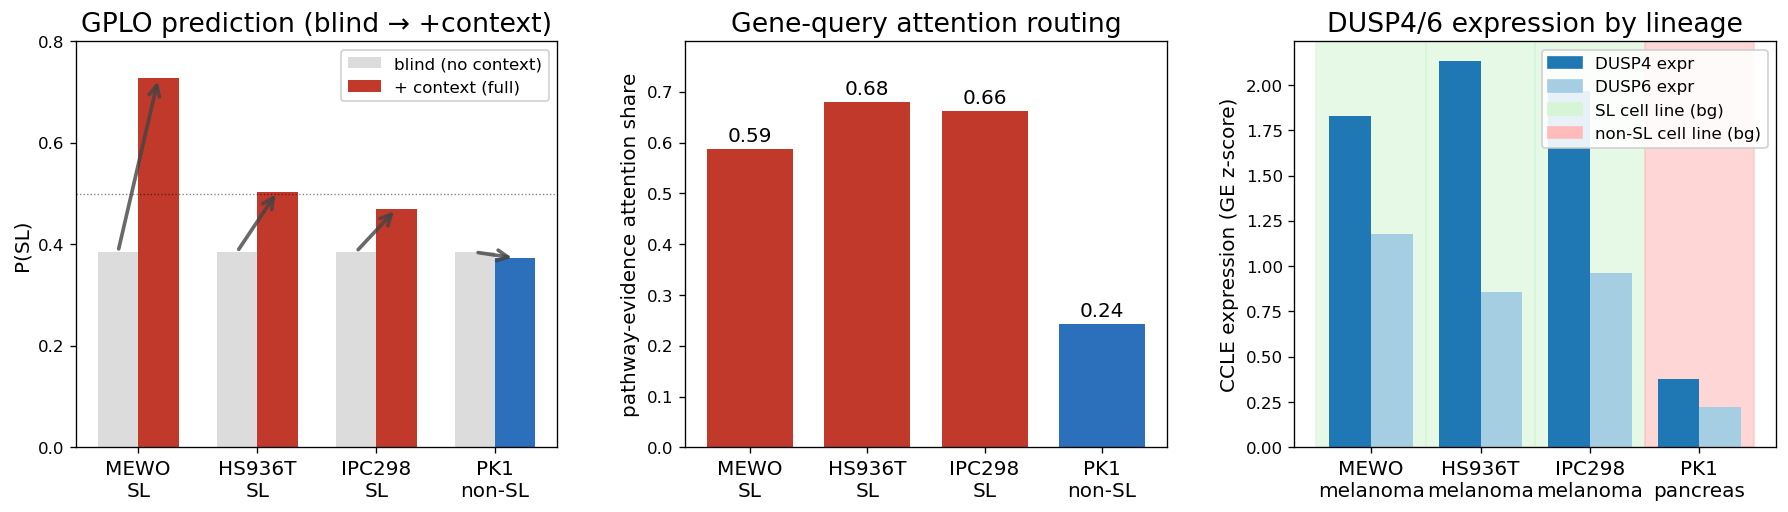

PRIMARY DUSP4|DUSP6 : rel SL effect GPLO +0.19 · causal PPE-margin +0.19 · internal pathway-attn share SL~0.64 vs non-SL(PK1) 0.24


In [ ]:
import os, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.patches as mpatches
sys.path.insert(0, BASE); sys.path.insert(0, os.path.join(BASE, 'ana'))
import model_version as MV, attn_substrate as V
from src.pair_pathway import PairPathwayEvidenceBuilder
_pk = lambda g: '|'.join(sorted(str(g).split('|')))
def LD(p):
    d = pd.read_csv(p); d['pk'] = d.gene_pair.map(_pk); return d
GP = LD(MV.PRED_GPLO); GBL = LD(MV.PRED_BLIND_GPLO)
SW = pd.read_csv(MV.OMICS_SWAP_FULL); SW['pk'] = SW.gene_pair.map(_pk)
RREC, _, PDF = V.build_substrate(MV.ATTN_PKL, 16); PDF['pk'] = PDF.pair.map(_pk)
def pcl(df, pk): return df[df.pk == pk].groupby('cell_line').agg(prob=('prob', 'mean'), label=('label', 'first'))
def blindv(df, pk): return df[df.pk == pk].groupby('cell_line').prob.mean()
def margin(pk):
    d = SW[SW.pk == pk].copy(); cl = d.groupby('cell_line').label.first()
    d['ctx'] = d.context_cl.map(cl); d = d.dropna(subset=['ctx'])
    return d[d.ctx == 1].prob.mean() - d[d.ctx == 0].prob.mean()
def evid_ratio(pk):   # model-internal: gene-query cross-attn share on the pathway-evidence tokens, per cell line
    return (pd.DataFrame([(x['cell_line'], x['evidence_ratio']) for x in RREC if _pk(x['gene_pair']) == pk],
                         columns=['cl', 'er']).groupby('cl').er.mean())
bld = PairPathwayEvidenceBuilder(k=16)
def expr(g, cl): return float(bld.gom_by_cl[cl][bld.gene_row[g], 0])
SLc, NSc = '#c0392b', '#2c6fbb'     # SL = red (uniform), non-SL = blue
GREY = '#dcdcdc'                    # no-context blind bars

# ============================ tunable knobs ============================
# A - blind->context paired bars (grey blind, coloured full, diagonal shift arrow)
BAR_W_A      = 0.34                               # bar width within a cell-line group
ARROW_LW_A   = 2.2                                # blind->context shift arrow line width
ARROW_HEAD_A = 16                                 # arrow-head size (scales with the thicker line)
# B — attention-routing bars: thinner bars, but the GAP between bars stays FIXED (x-step = width + gap)
BAR_W_B = 0.55                                    # attention-routing bar width
GAP_B   = 0.20                                    # gap between adjacent bars — held CONSTANT when BAR_W_B changes
# D - DUSP4/6 expression colours (colour-vision-deficiency checked)
D_SCHEMES = {
    'teal_orange': ('#1b9e77', '#d95f02'),       # Dark2 teal/orange
    'purple_teal': ('#762a83', '#1b9e77'),       # purple/teal — highest separation (ΔE 22.1), pure cool, no red-clash
    'cus':  ('#1f78b4', '#a6cee3'),       # brown/teal — earthy, all pass (ΔE 11.0)
    'purple_gold': ('#7d3c98', '#d68910'),
}
D_SCHEME = 'cus'                          # selected colour scheme
C_DUSP4, C_DUSP6 = D_SCHEMES[D_SCHEME]
SL_BG, NSL_BG = '#d6f5d6', '#ffbbbb'             # D-panel per-cell-line background: SL = light green, non-SL = light red
BG_ALPHA = 0.6                                    # background tint strength
# ======================================================================

PK = 'DUSP4|DUSP6'
gf = pcl(GP, PK); gb = blindv(GBL, PK)
CELLS = ['MEWO', 'HS936T', 'IPC298', 'PK1']
GENO = {'MEWO': 'melanoma', 'HS936T': 'melanoma', 'IPC298': 'melanoma', 'PK1': 'pancreas'}
LABEL = {c: int(gf.loc[c, 'label']) for c in CELLS}
def cbar(c): return SLc if LABEL[c] == 1 else NSc     # SL uniform red
def relgap(full): return np.mean([full.loc[c, 'prob'] for c in CELLS if LABEL[c] == 1]) - np.mean([full.loc[c, 'prob'] for c in CELLS if LABEL[c] == 0])

fig, (axA, axB, axD) = plt.subplots(1, 3, figsize=(15, 4.7)); x = np.arange(len(CELLS))

# A. GPLO prediction: no-context blind -> +context (diagonal shift arrow blind bar -> full bar)
axA.bar(x - BAR_W_A/2, [gb[c] for c in CELLS], BAR_W_A, color=GREY, label='blind (no context)')
axA.bar(x + BAR_W_A/2, [gf.loc[c, 'prob'] for c in CELLS], BAR_W_A, color=[cbar(c) for c in CELLS], label='+ context (full)')
for i, c in enumerate(CELLS):
    axA.annotate('', xy=(i + BAR_W_A/2, gf.loc[c, 'prob']), xytext=(i - BAR_W_A/2, gb[c]),
                 arrowprops=dict(arrowstyle='->', color='#444', lw=ARROW_LW_A, alpha=.8, mutation_scale=ARROW_HEAD_A))
axA.axhline(.5, ls=':', c='k', lw=.8, alpha=.5)
axA.set_xticks(x); axA.set_xticklabels([f"{c}\n{'SL' if LABEL[c] == 1 else 'non-SL'}" for c in CELLS], fontsize=12)
axA.set_ylim(0, 0.8); axA.set_yticks(np.arange(0, 0.81, 0.2)); axA.set_ylabel('P(SL)', fontsize=12)
bgap = np.mean([gb[c] for c in CELLS if LABEL[c] == 1]) - np.mean([gb[c] for c in CELLS if LABEL[c] == 0])
axA.set_title(f"GPLO prediction (blind → +context)", fontsize=16)
_handles_A = [
    mpatches.Patch(facecolor=GREY, label='blind (no context)'),
    mpatches.Patch(facecolor=SLc,  label='SL (+ context)'),
    mpatches.Patch(facecolor=NSc,  label='non-SL (+ context)'),
]
axA.legend(handles=_handles_A, fontsize=10, loc='upper right', framealpha=.9)

# B. MODEL-INTERNAL: gene-query cross-attention routing (share on pathway-evidence tokens)
#    x-step tracks (BAR_W_B + GAP_B) so thinning the bars does NOT change the gap between them.
xB = np.arange(len(CELLS)) * (BAR_W_B + GAP_B)
er = evid_ratio(PK); vals = [float(er.get(c, np.nan)) for c in CELLS]
axB.bar(xB, vals, BAR_W_B, color=[cbar(c) for c in CELLS])
for i, v in enumerate(vals): axB.text(xB[i], v + 0.015, f"{v:.2f}", ha='center', fontsize=12)
axB.set_xticks(xB); axB.set_xticklabels([f"{c}\n{'SL' if LABEL[c] == 1 else 'non-SL'}" for c in CELLS], fontsize=12)
axB.set_ylim(0, max(vals) + 0.12); axB.set_ylabel('pathway-evidence attention share', fontsize=12)
axB.set_title("Gene-query attention routing", fontsize=16)

# D. Expression values (CCLE). Background tint = SL (green) / non-SL (light red).
wD = 0.38
for i, c in enumerate(CELLS): axD.axvspan(i - .5, i + .5, color=(SL_BG if LABEL[c] == 1 else NSL_BG), alpha=BG_ALPHA, zorder=0)
axD.bar(x - wD/2, [expr('DUSP4', c) for c in CELLS], wD, color=C_DUSP4, label='DUSP4 expr', zorder=2)
axD.bar(x + wD/2, [expr('DUSP6', c) for c in CELLS], wD, color=C_DUSP6, label='DUSP6 expr', zorder=2)
axD.axhline(0, color='k', lw=.6, zorder=1); axD.set_xticks(x); axD.set_xticklabels([f"{c}\n{GENO[c]}" for c in CELLS], fontsize=12)
axD.set_ylabel('CCLE expression (GE z-score)', fontsize=12)
axD.set_title("DUSP4/6 expression by lineage", fontsize=16)
axD.legend(handles=[mpatches.Patch(color=C_DUSP4, label='DUSP4 expr'), mpatches.Patch(color=C_DUSP6, label='DUSP6 expr'),
                    mpatches.Patch(color=SL_BG, label='SL cell line (bg)'), mpatches.Patch(color=NSL_BG, label='non-SL cell line (bg)')],
          fontsize=10, loc='upper right', framealpha=.9)

plt.tight_layout(rect=[0, 0, 1, 0.93], w_pad=3.2)
plt.savefig(os.path.join(BASE, 'ana/fig_dusp_case.png'), dpi=140, bbox_inches='tight'); plt.show()

slr = np.nanmean([er.get(c, np.nan) for c in CELLS if LABEL[c] == 1])
print(f"DUSP4|DUSP6 : relative SL effect (GPLO) {relgap(gf):+.2f} · PPE-swap margin {margin(PK):+.2f} · pathway-attn share SL~{slr:.2f} vs non-SL(PK1) {er.get('PK1', np.nan):.2f}")


In [8]:
# ============================ tunable knobs ============================
# A - blind->context paired bars (grey blind, coloured full, diagonal shift arrow)
BAR_W_A      = 0.34                               # bar width within a cell-line group
ARROW_LW_A   = 2.2                                # blind->context shift arrow line width
ARROW_HEAD_A = 16                                 # arrow-head size (scales with the thicker line)
# B — attention-routing bars: thinner bars, but the GAP between bars stays FIXED (x-step = width + gap)
BAR_W_B = 0.45                                    # attention-routing bar width
GAP_B   = 0.20                                    # gap between adjacent bars — held CONSTANT when BAR_W_B changes
# D - DUSP4/6 expression colours (colour-vision-deficiency checked)
D_SCHEMES = {
    'teal_orange': ('#1b9e77', '#d95f02'),       # Dark2 teal/orange
    'purple_teal': ('#762a83', '#1b9e77'),       # purple/teal — highest separation (ΔE 22.1), pure cool, no red-clash
    'cus':  ('#1f78b4', '#a6cee3'),       # brown/teal — earthy, all pass (ΔE 11.0)
    'purple_gold': ('#7d3c98', '#d68910'),
}
D_SCHEME = 'cus'                          # selected colour scheme
C_DUSP4, C_DUSP6 = D_SCHEMES[D_SCHEME]
SL_BG, NSL_BG = '#d6f5d6', '#ffbbbb'             # D-panel per-cell-line background: SL = light green, non-SL = light red
BG_ALPHA = 0.6                                    # background tint strength
# ======================================================================


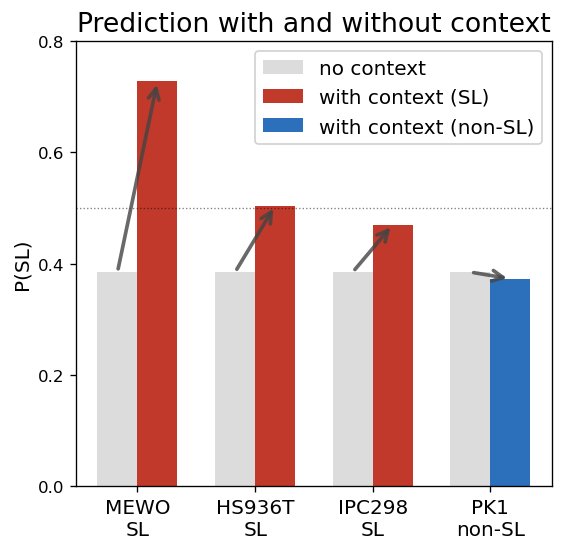

In [11]:
# ========================= Figure 1: GPLO prediction only =========================
x = np.arange(len(CELLS))

fig, axA = plt.subplots(figsize=(4.8, 4.7))

# A. GPLO prediction: no-context blind -> +context
axA.bar(
    x - BAR_W_A/2,
    [gb[c] for c in CELLS],
    BAR_W_A,
    color=GREY,
    label='no context'
)

axA.bar(
    x + BAR_W_A/2,
    [gf.loc[c, 'prob'] for c in CELLS],
    BAR_W_A,
    color=[cbar(c) for c in CELLS],
    label='with context'
)

# blind -> context shift arrows
for i, c in enumerate(CELLS):
    axA.annotate(
        '',
        xy=(i + BAR_W_A/2, gf.loc[c, 'prob']),
        xytext=(i - BAR_W_A/2, gb[c]),
        arrowprops=dict(
            arrowstyle='->',
            color='#444',
            lw=ARROW_LW_A,
            alpha=.8,
            mutation_scale=ARROW_HEAD_A
        )
    )

axA.axhline(.5, ls=':', c='k', lw=.8, alpha=.5)

axA.set_xticks(x)
axA.set_xticklabels(
    [f"{c}\n{'SL' if LABEL[c] == 1 else 'non-SL'}" for c in CELLS],
    fontsize=12
)

axA.set_ylim(0, 0.8)
axA.set_yticks(np.arange(0, 0.81, 0.2))
axA.set_ylabel('P(SL)', fontsize=12)

bgap = (
    np.mean([gb[c] for c in CELLS if LABEL[c] == 1])
    - np.mean([gb[c] for c in CELLS if LABEL[c] == 0])
)

axA.set_title("Prediction with and without context", fontsize=16)
import matplotlib.patches as mpatches
_handles_A = [
    mpatches.Patch(facecolor=GREY, label='no context'),
    mpatches.Patch(facecolor=SLc,  label='with context (SL)'),
    mpatches.Patch(facecolor=NSc,  label='with context (non-SL)'),
]
axA.legend(handles=_handles_A, fontsize=12, loc='upper right', framealpha=.9)

plt.tight_layout()

plt.savefig(
    os.path.join(BASE, 'ana/fig_dusp_prediction.png'),
    dpi=140,
    bbox_inches='tight'
)
plt.show()


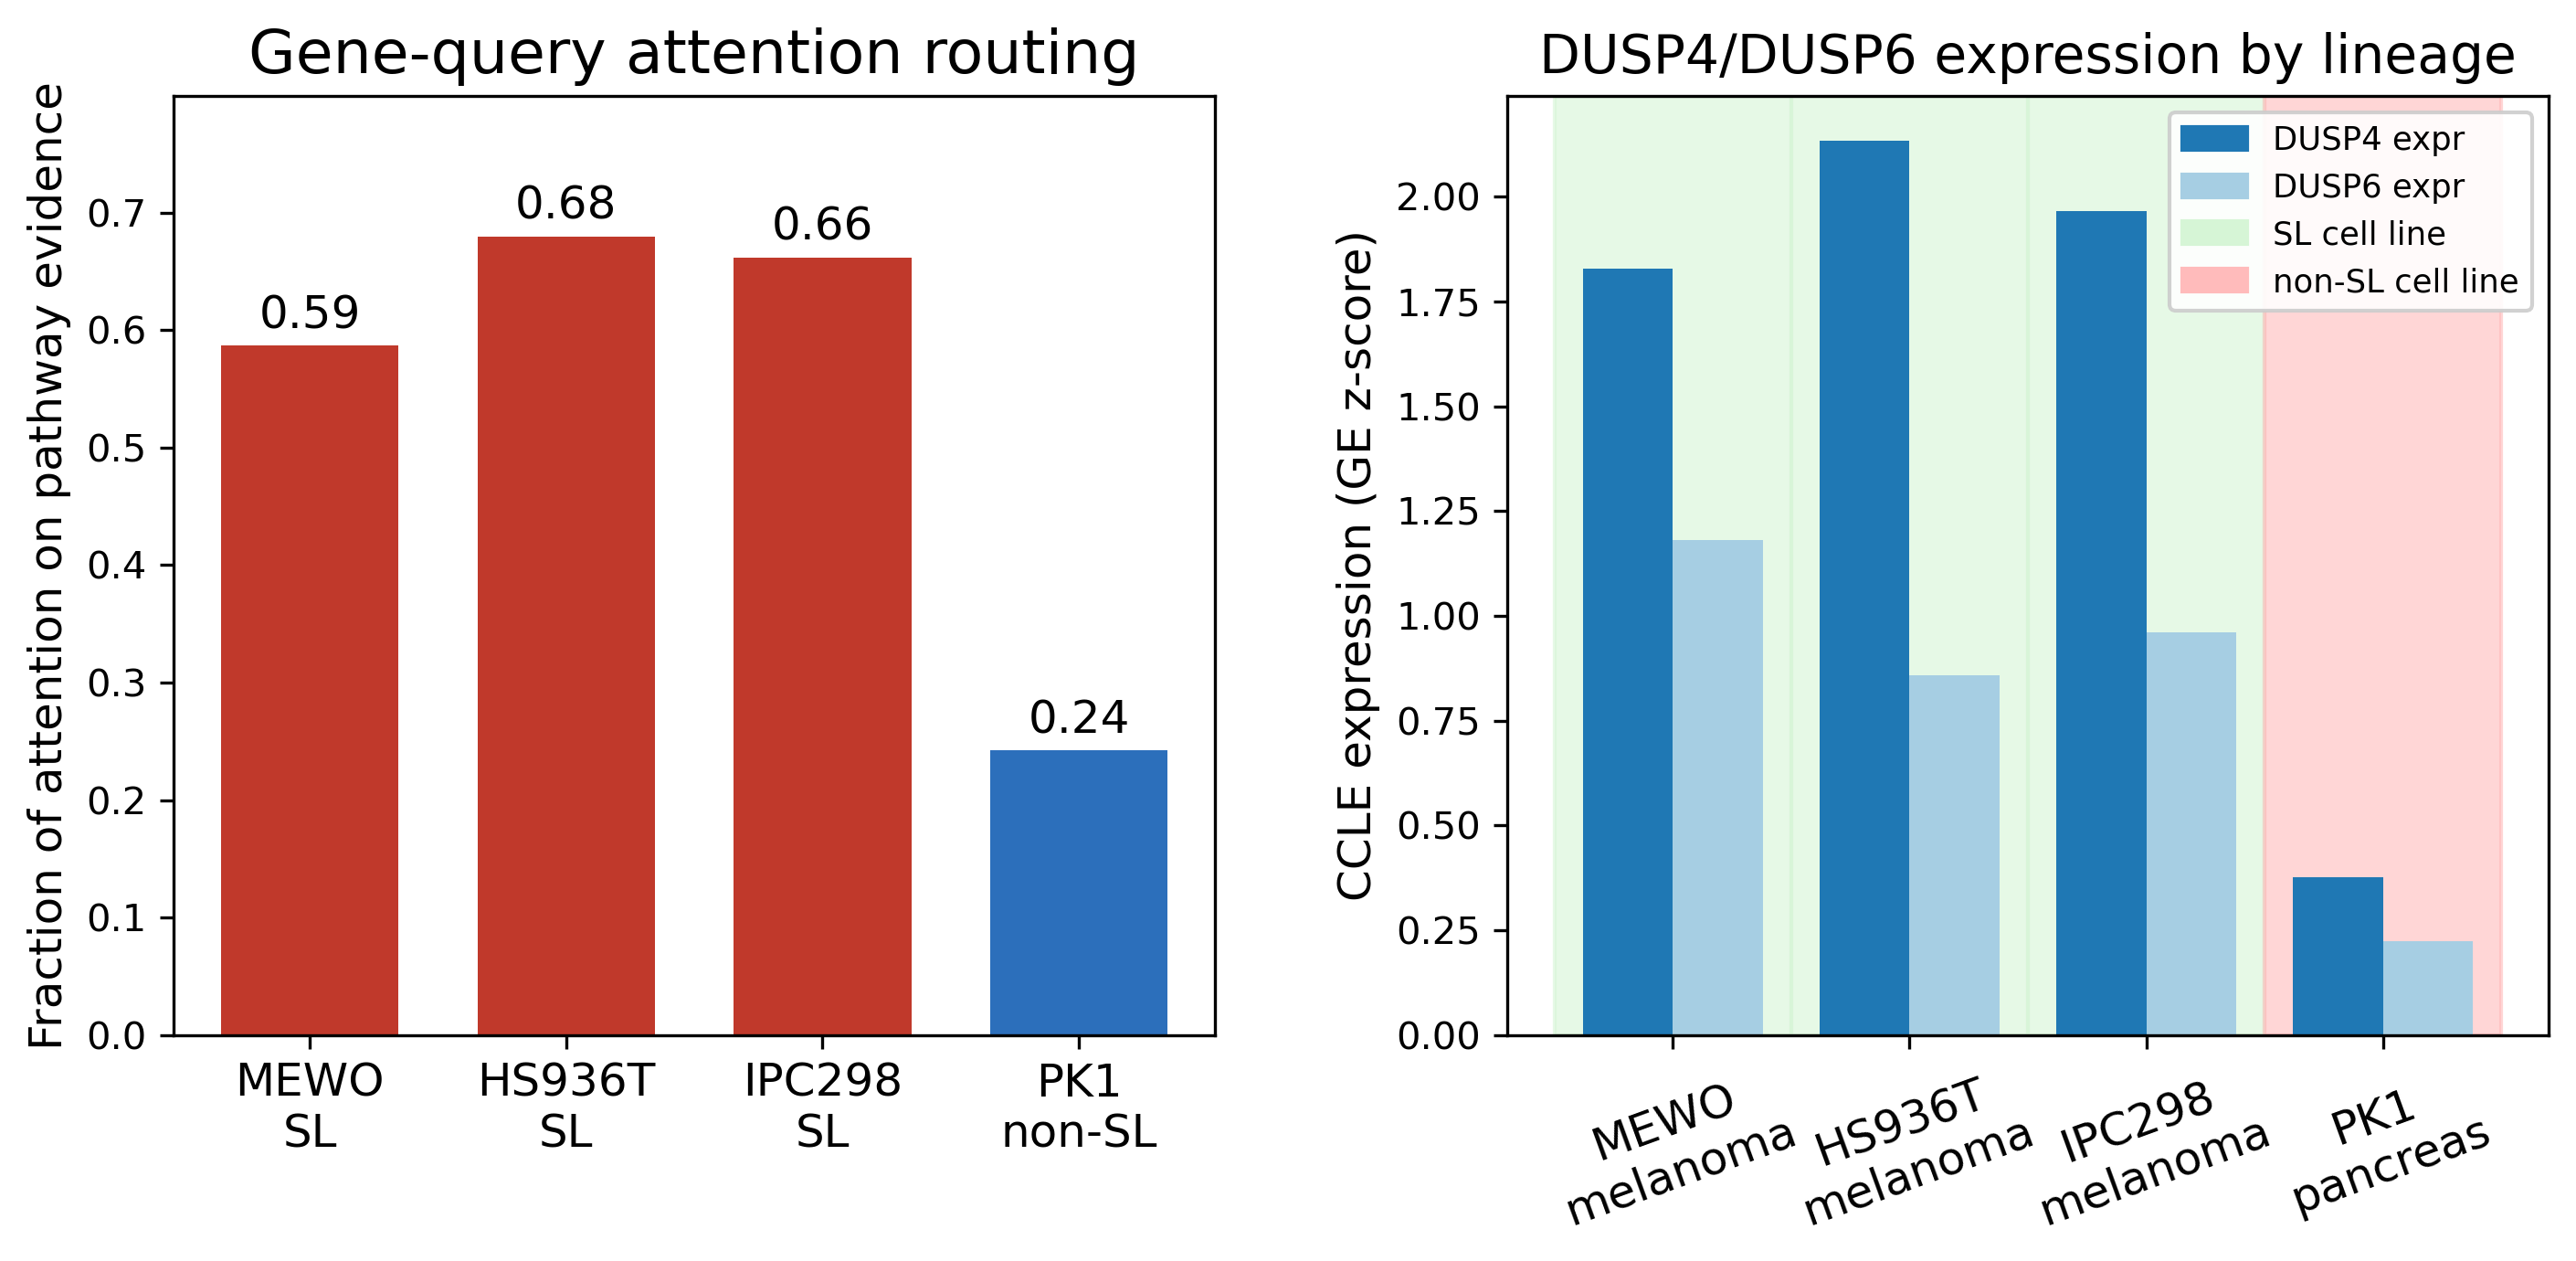

PRIMARY DUSP4|DUSP6 : rel SL effect GPLO +0.19 · causal PPE-margin +0.19 · internal pathway-attn share SL~0.64 vs non-SL(PK1) 0.24


In [24]:
# ================= Figure 2: routing + expression =================
fig, (axB, axD) = plt.subplots(1, 2, figsize=(9.5, 4.7),dpi=300)

# ---- A. Gene-query attention routing ----
ATTN_SL, ATTN_NSL = '#ea0017', '#2166ac'   # <- panel A colours

xB = np.arange(len(CELLS)) * (BAR_W_B + GAP_B)
er = evid_ratio(PK)
vals = [float(er.get(c, np.nan)) for c in CELLS]


axB.bar(xB, vals, BAR_W_B, color=[cbar(c) for c in CELLS])
for xi, v in zip(xB, vals):
    axB.text(xi, v + .015, f'{v:.2f}', ha='center', fontsize=12)

axB.set(
    xticks=xB,
    ylim=(0, max(vals) + .12),
    ylabel='Fraction of attention on pathway evidence',
    title='Gene-query attention routing'
)
axB.set_xticklabels(
    [f"{c}\n{'SL' if LABEL[c] else 'non-SL'}" for c in CELLS],
    fontsize=12
)
axB.title.set_fontsize(16)
axB.yaxis.label.set_fontsize(12)


# ---- B. DUSP4/6 expression ----
x = np.arange(len(CELLS))
wD = .38

for i, c in enumerate(CELLS):
    axD.axvspan(
        i-.5, i+.5,
        color=SL_BG if LABEL[c] else NSL_BG,
        alpha=BG_ALPHA,
        zorder=0
    )

axD.bar(x-wD/2, [expr('DUSP4', c) for c in CELLS],
        wD, color=C_DUSP4, zorder=2)
axD.bar(x+wD/2, [expr('DUSP6', c) for c in CELLS],
        wD, color=C_DUSP6, zorder=2)

axD.axhline(0, color='k', lw=.6, zorder=1)
axD.set(
    xticks=x,
    ylabel='CCLE expression (GE z-score)',
    title='DUSP4/DUSP6 expression by lineage'
)
axD.set_xticklabels([f'{c}\n{GENO[c]}' for c in CELLS], fontsize=12, rotation=20)
axD.title.set_fontsize(14)
axD.yaxis.label.set_fontsize(12)

axD.legend(
    handles=[
        mpatches.Patch(color=C_DUSP4, label='DUSP4 expr'),
        mpatches.Patch(color=C_DUSP6, label='DUSP6 expr'),
        mpatches.Patch(color=SL_BG, label='SL cell line'),
        mpatches.Patch(color=NSL_BG, label='non-SL cell line')
    ],
    fontsize=8.5, loc='upper right', framealpha=.9
)

plt.tight_layout(w_pad=3.2)
plt.savefig(
    os.path.join(BASE, 'ana/fig_dusp_routing_expression.png'),
    dpi=140, bbox_inches='tight'
)
plt.show()

slr = np.nanmean([er.get(c, np.nan) for c in CELLS if LABEL[c] == 1])
print(
    f"PRIMARY DUSP4|DUSP6 : rel SL effect GPLO {relgap(gf):+.2f} · "
    f"causal PPE-margin {margin(PK):+.2f} · "
    f"internal pathway-attn share SL~{slr:.2f} vs "
    f"non-SL(PK1) {er.get('PK1', np.nan):.2f}"
)


### DUSP4|DUSP6 @ HS936T - pathway-evidence attention


In [11]:
import os, sys, re
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
sys.path.insert(0, os.path.join(BASE, 'ana'))
import attn_substrate as V, mechanism_alignment as M, lit_mech_casestudy as L, model_version as MV

# ---------------- knobs ----------------
PK, CL  = 'DUSP4|DUSP6', 'HS936T'
CMAP    = plt.cm.Blues          # sequential single hue = mechanism-percentile magnitude
ACCENT  = '#b2182b'             # MAPK mechanism-pathway highlight (outline + bold label)
FIGSIZE = (10.4, 6.0)
# ---------------------------------------

# mechanism vector (BiomedBERT cache, offline) -> cosine vs every Reactome name -> percentile scale
pw_emb, mech_emb, pks, _ = M.build_embeddings()
mvec   = mech_emb[pks.index(PK)]
allcos = pw_emb @ mvec
PN     = V.PNAMES

# HS936T-specific per-pathway attention for this pair
_, _, PDF = V.build_substrate(MV.ATTN_PKL, 16)
PDF['pk'] = PDF.pair.map(lambda g: '|'.join(sorted(str(g).split('|'))))
sub  = PDF[(PDF.pk == PK) & (PDF.cl == CL)]
a    = sub.groupby('pidx').attn.mean()
pidx = a.index.values.astype(int); attn = a.values.astype(float)
cos  = allcos[pidx]; pct = np.array([(allcos < c).mean() for c in cos])
name = [PN[i].replace('REACTOME_', '') for i in pidx]
df   = pd.DataFrame(dict(pathway=name, attn=attn, pctile=pct)).sort_values('attn').reset_index(drop=True)

MAPK       = re.compile(dict(L.THEMES)['MAPK / RAF-ERK'], re.I)
df['mapk'] = df.pathway.map(lambda s: bool(MAPK.search(s)))
mapk_mass  = df.attn[df.mapk].sum() / df.attn.sum()


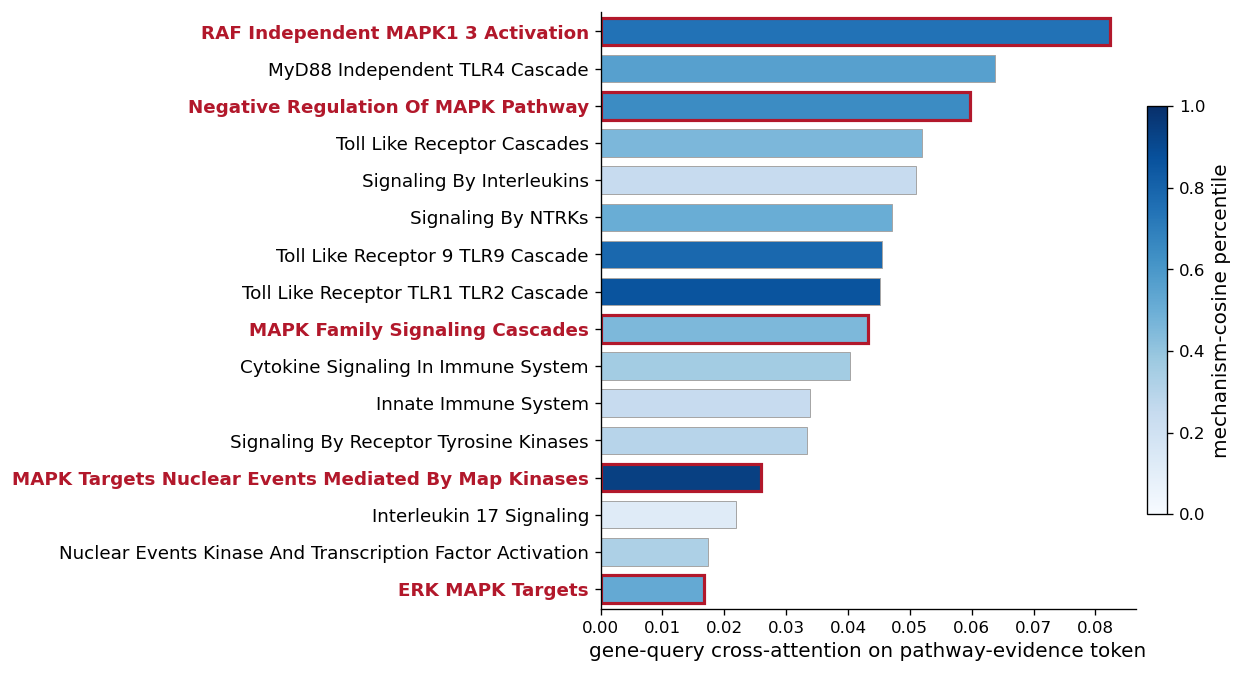

DUSP4|DUSP6 @ HS936T: MAPK-strict 5/16 tokens = 33.6% of pathway attention mass (31% by count)
top-3 attended: RAF Independent MAPK1 3 Activation (attn 0.082, pctile 0.75); MyD88 Independent TLR4 Cascade (attn 0.064, pctile 0.56); Negative Regulation Of MAPK Pathway (attn 0.060, pctile 0.65)


In [ ]:
# ---------------- knobs ----------------
PK, CL  = 'DUSP4|DUSP6', 'HS936T'
CMAP    = plt.cm.Blues          # sequential single hue = mechanism-percentile magnitude
ACCENT  = '#b2182b'             # MAPK mechanism-pathway highlight (red edge + bold label)
FIGSIZE = (10.4, 6.0)
LBL_FS  = 11                    # y-axis pathway label font size
# ---------------------------------------

def pretty(s):
    t = s.replace('_', ' ').title()
    for a_, b_ in [('Mapk', 'MAPK'), ('Erk', 'ERK'), ('Raf', 'RAF'), ('Mek', 'MEK'), ('Tlr', 'TLR'),
                   ('Ntrk', 'NTRK'), ('Myd88', 'MyD88'), ('Rtk', 'RTK'), ('Il ', 'IL-')]:
        t = t.replace(a_, b_)
    return t
labels = [pretty(p) for p in df.pathway]      # MAPK identity is shown by bold + red label/edge

fig, ax = plt.subplots(figsize=FIGSIZE)
norm = mpl.colors.Normalize(0, 1)
bars = ax.barh(range(len(df)), df.attn, height=0.74,
               color=CMAP(norm(df.pctile)), edgecolor='0.65', linewidth=0.6)
for i, m in enumerate(df.mapk):
    if m:
        bars[i].set_edgecolor(ACCENT); bars[i].set_linewidth(1.9)
ax.set_yticks(range(len(df))); ax.set_yticklabels(labels, fontsize=LBL_FS)
for lbl, m in zip(ax.get_yticklabels(), df.mapk):
    if m:
        lbl.set_color(ACCENT); lbl.set_fontweight('bold')

ax.set_xlabel('gene-query cross-attention on pathway-evidence token', fontsize=12)
ax.margins(y=0.01)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)

sm = plt.cm.ScalarMappable(cmap=CMAP, norm=norm); sm.set_array([])
cb = fig.colorbar(sm, ax=ax, fraction=0.036, pad=0.02)
cb.set_label('mechanism-cosine percentile', fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

print(f'DUSP4|DUSP6 @ {CL}: MAPK-strict {int(df.mapk.sum())}/{len(df)} tokens = '
      f'{mapk_mass * 100:.1f}% of pathway attention mass ({df.mapk.mean() * 100:.0f}% by count)')
top3 = df.sort_values('attn', ascending=False).head(3)
print('top-3 attended:', '; '.join(f'{pretty(p)} (attn {v:.3f}, pctile {q:.2f})'
      for p, v, q in zip(top3.pathway, top3.attn, top3.pctile)))


### DUSP4|DUSP6 pathway evidence across cell lines


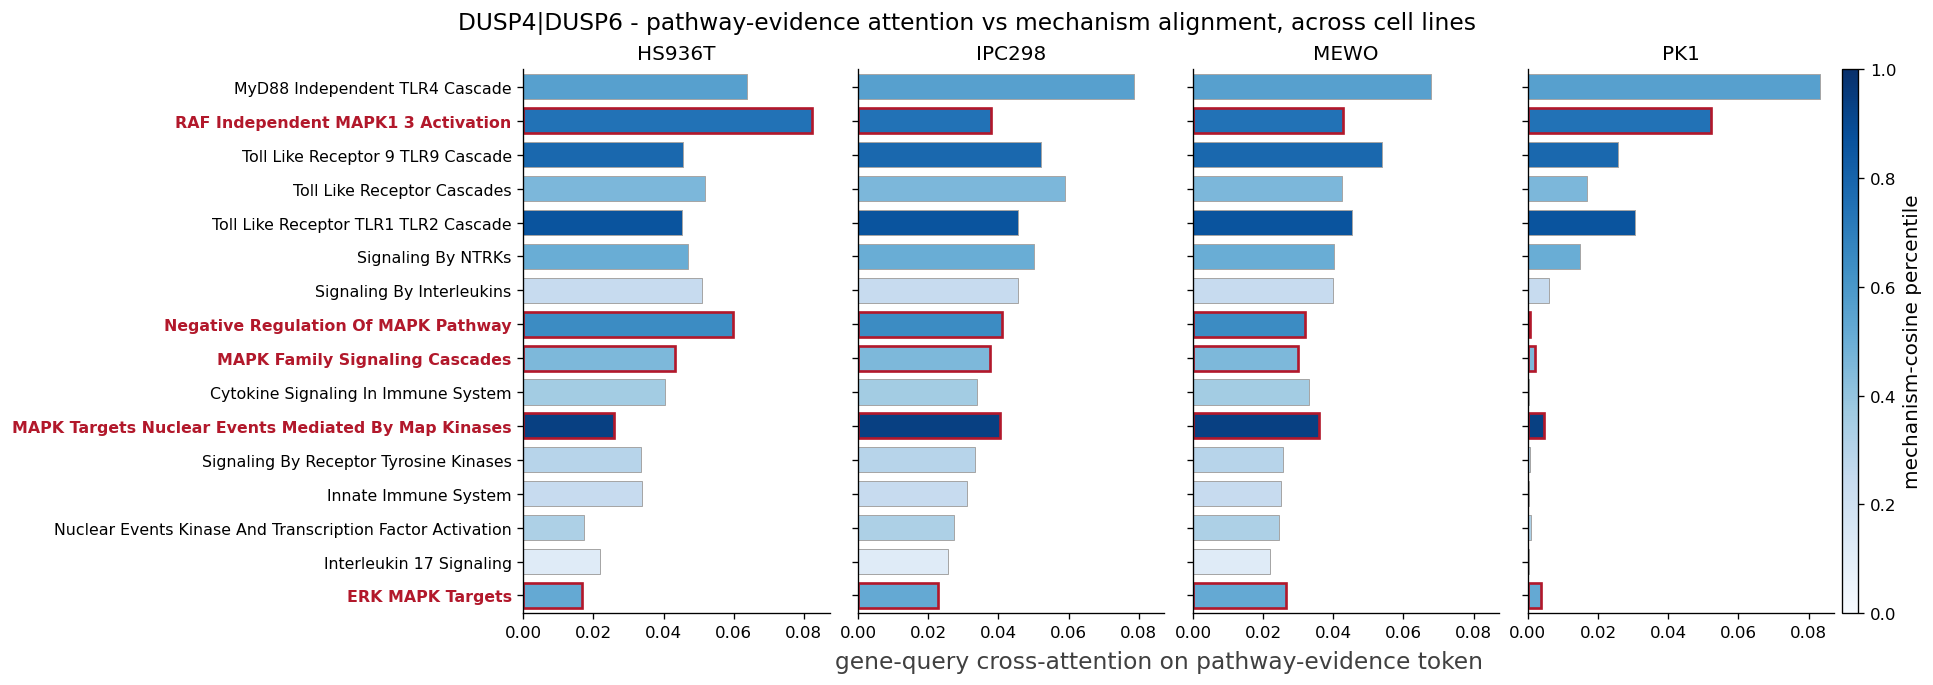

DUSP4|DUSP6 - MAPK-strict 5/16 of the pair-conditioned evidence tokens

cell_line lineage  label   subset  mapk_mass  block_attn                               top1  top1_is_mapk  top1_pctile
   HS936T     mel      1 conflict      0.336       0.679 RAF Independent MAPK1 3 Activation          True         0.75
   IPC298     mel      1 conflict      0.272       0.662     MyD88 Independent TLR4 Cascade         False         0.56
     MEWO     mel      1 conflict      0.284       0.587     MyD88 Independent TLR4 Cascade         False         0.56
      PK1  nonmel      0 conflict      0.260       0.242     MyD88 Independent TLR4 Cascade         False         0.56

MAPK mass range across cell lines: 0.260 - 0.336  (spread 7.6 pp)

row order in use (ORDER='mean'), top -> bottom. Copy this list, reorder it by hand, and
paste it back into the ORDER knob to take full manual control of the y axis:
ORDER = ['MYD88_INDEPENDENT_TLR4_CASCADE', 'RAF_INDEPENDENT_MAPK1_3_ACTIVATION',
         'TOLL_LIKE

In [13]:

# ---------------- knobs ----------------
CLS    = sorted(PDF[PDF.pk == PK].cl.unique())   # 4 of the 6 cell lines carry this pair in GPLO test
MAIN   = CL                                      # the cell line shown in the main text (§7c) -> flagged
# ORDER  = CL 
ORDER  = 'mean'
FIGSZ  = (16, 5.6)
LBL_FS = 9.5
# ---------------------------------------
subA = PDF[PDF.pk == PK]
A    = {cl: subA[subA.cl == cl].groupby('pidx').attn.mean() for cl in CLS}
pidx = A[CLS[0]].index.values.astype(int)
assert all((A[cl].index.values.astype(int) == pidx).all() for cl in CLS), 'token set differs across cl'
name0 = [PN[i].replace('REACTOME_', '') for i in pidx]
pct0  = np.array([(allcos < allcos[i]).mean() for i in pidx])
mapk0 = np.array([bool(MAPK.search(s)) for s in name0])
mat0  = np.vstack([A[cl].values.astype(float) for cl in CLS])         # (n_cl, 16)

def resolve_order(spec):
    """ORDER knob -> list of column indices in DISPLAY order (top row first)."""
    mean = mat0.mean(axis=0)
    if isinstance(spec, str):
        if spec in CLS:      return list(np.argsort(-mat0[CLS.index(spec)]))
        if spec == 'mean':   return list(np.argsort(-mean))
        if spec == 'pctile': return list(np.argsort(-pct0))
        if spec == 'mapk':   return list(np.lexsort((-mean, ~mapk0)))   # ~True=0 -> MAPK rows first
        raise ValueError(f'ORDER={spec!r}: use one of {CLS} / "mean" / "pctile" / "mapk" / a list')
    rows, used = [], set()
    for s in spec:
        q   = str(s).upper().replace(' ', '_')
        hit = [j for j, n in enumerate(name0) if q in n.upper() and j not in used]
        if len(hit) != 1:
            raise ValueError(f'ORDER entry {s!r} matched {len(hit)} unused pathways - be more specific')
        rows.append(hit[0]); used.add(hit[0])
    return rows + [j for j in np.argsort(-mean) if j not in used]      # omitted ones keep 'mean' order

order = resolve_order(ORDER)[::-1]                        # barh draws index 0 at the BOTTOM -> reverse
name, pct, mapk, mat = [name0[i] for i in order], pct0[order], mapk0[order], mat0[:, order]
meta = {cl: subA[subA.cl == cl].iloc[0] for cl in CLS}

fig, axes = plt.subplots(1, len(CLS), figsize=FIGSZ, sharey=True, sharex=True, layout='constrained')
norm = mpl.colors.Normalize(0, 1)
for k, (cl, ax) in enumerate(zip(CLS, axes)):
    bars = ax.barh(range(len(name)), mat[k], height=.74,
                   color=CMAP(norm(pct)), edgecolor='0.65', linewidth=.6)
    for i, m in enumerate(mapk):
        if m:
            bars[i].set_edgecolor(ACCENT); bars[i].set_linewidth(1.6)
    mass = mat[k][mapk].sum() / mat[k].sum()
    am   = int(np.argmax(mat[k]))
    t1   = 'MAPK' if mapk[am] else pretty(name[am]).split()[0]        # short tag for the #1 token
    ax.set_title(f'{cl}',
                fontsize=12)
    ax.margins(y=.01)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
axes[0].set_yticks(range(len(name))); axes[0].set_yticklabels([pretty(p) for p in name], fontsize=LBL_FS)
for lbl, m in zip(axes[0].get_yticklabels(), mapk):
    if m:
        lbl.set_color(ACCENT); lbl.set_fontweight('bold')

sm = plt.cm.ScalarMappable(cmap=CMAP, norm=norm); sm.set_array([])
cb = fig.colorbar(sm, ax=axes, fraction=.016, pad=.006, aspect=34)
cb.set_label('mechanism-cosine percentile', fontsize=12)
fig.suptitle(f'{PK} - pathway-evidence attention vs mechanism alignment, across cell lines', fontsize=14)
fig.supxlabel('gene-query cross-attention on pathway-evidence token',
            #   'across panels — only bar length is cell-line specific)', 
              fontsize=14, color='0.25',x=0.6)
plt.show()

summary = pd.DataFrame([dict(
    cell_line=cl, lineage=meta[cl].lin, label=int(meta[cl].label), subset=meta[cl].subset,
    mapk_mass=round(float(mat[k][mapk].sum() / mat[k].sum()), 3),
    block_attn=round(float(mat[k].sum()), 3),
    top1=pretty(name[int(np.argmax(mat[k]))]),
    top1_is_mapk=bool(mapk[int(np.argmax(mat[k]))]),
    top1_pctile=round(float(pct[int(np.argmax(mat[k]))]), 2),
) for k, cl in enumerate(CLS)])
print(f'{PK} - MAPK-strict {int(mapk.sum())}/{len(name)} of the pair-conditioned evidence tokens\n')
print(summary.to_string(index=False))
print(f'\nMAPK mass range across cell lines: {summary.mapk_mass.min():.3f} - {summary.mapk_mass.max():.3f}'
      f'  (spread {100 * (summary.mapk_mass.max() - summary.mapk_mass.min()):.1f} pp)')

import textwrap
print(f'\nrow order in use (ORDER={ORDER!r}), top -> bottom. Copy this list, reorder it by hand, and\n'
      'paste it back into the ORDER knob to take full manual control of the y axis:')
print(textwrap.fill('ORDER = ' + repr(list(name[::-1])), width=112, subsequent_indent=' ' * 9))
